# MAGFiLO 2026 - Solar Filament Segmentation (YOLO11x-seg)

Cleaned up and split into separate cells, each with its real output from the run that
produced them. The section that previously crashed with `CUDA OutOfMemoryError`
(batched inference over all 180 test images at once) has been removed entirely and
replaced with a memory-safe, one-image-at-a-time version that also resolves
overlapping masks live during inference, so the resulting `submission.csv` has zero
overlapping pixels between instances without needing a separate post-processing pass.

See the explanation message alongside this notebook for what each cell does, the
model used, the loss terms, and the final validation metrics - for your mentor review.

## 1. Setup, dataset conversion (COCO -> YOLO format), ground-truth visualization

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 4.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
DATA ROOT : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
TRAIN IMG : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images
TRAIN ANN : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
TEST IMG  : /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images

Dataset paths veri

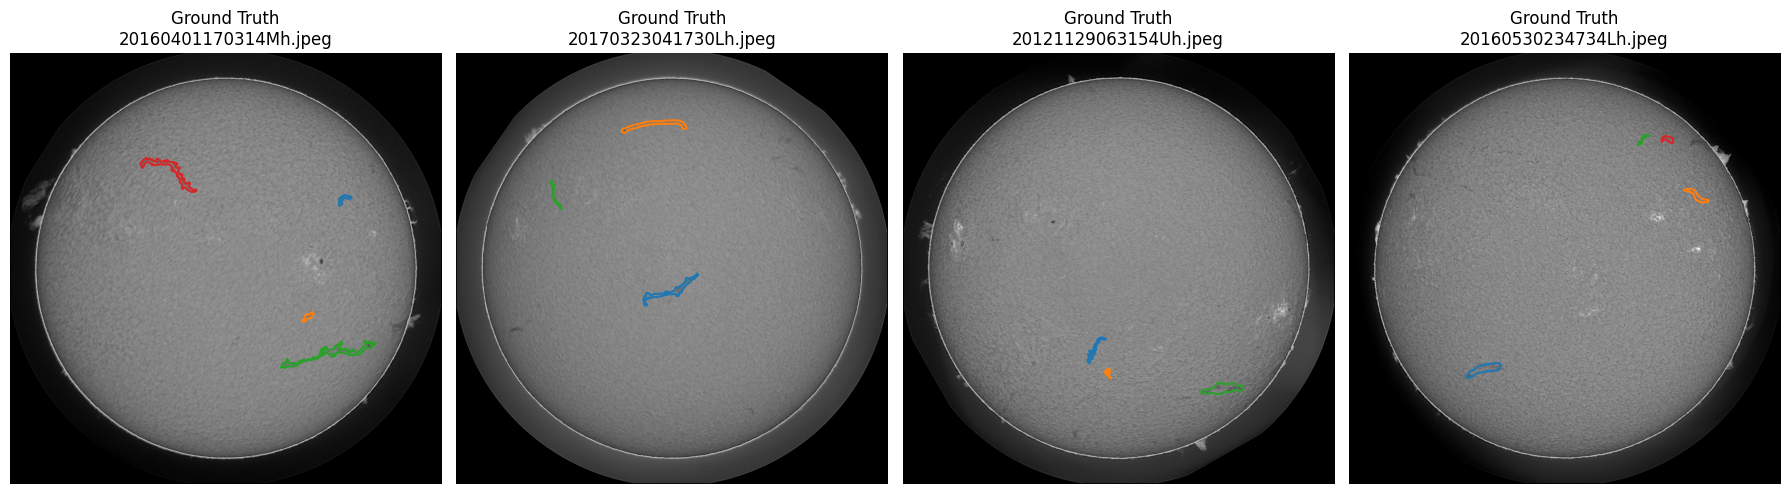

In [1]:
# ============================================================
# 1. INSTALL PACKAGES
# ============================================================

!pip install -q ultralytics pycocotools torchmetrics opencv-python-headless


# ============================================================
# 2. IMPORTS
# ============================================================

import os
import json
import random
import shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from collections import defaultdict

from pycocotools.coco import COCO
from pycocotools import mask as mask_utils

from ultralytics import YOLO


# ============================================================
# 3. CONFIGURATION
# ============================================================

DATA_ROOT = "/kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"

TRAIN_IMG = os.path.join(DATA_ROOT, "train", "train_images")
TRAIN_ANN = os.path.join(
    DATA_ROOT,
    "train",
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

TEST_IMG = os.path.join(DATA_ROOT, "test", "test_images")

WORK_DIR = "/kaggle/working/magfilo_yolo"
YOLO_ROOT = os.path.join(WORK_DIR, "yolo_dataset")

IMG_SIZE = 1024
BATCH = 8
EPOCHS = 15
VAL_SPLIT = 0.1
SEED = 42

MODEL_CFG = "yolo11x-seg.pt"

CLASS_NAMES = [
    "Left",
    "Right",
    "Unidentifiable",
    "Ambiguous"
]

CAT_ID_TO_YOLO = {
    1: 0,
    2: 1,
    3: 2,
    4: 3
}

NUM_CLASSES = len(CLASS_NAMES)

random.seed(SEED)
np.random.seed(SEED)

os.makedirs(WORK_DIR, exist_ok=True)

print("DATA ROOT :", DATA_ROOT)
print("TRAIN IMG :", TRAIN_IMG)
print("TRAIN ANN :", TRAIN_ANN)
print("TEST IMG  :", TEST_IMG)


# ============================================================
# 4. CHECK DATASET
# ============================================================

assert os.path.exists(TRAIN_IMG), "Training image directory not found"
assert os.path.exists(TRAIN_ANN), "Annotation JSON not found"
assert os.path.exists(TEST_IMG), "Test image directory not found"

print("\nDataset paths verified successfully.")


# ============================================================
# 5. LOAD COCO ANNOTATIONS
# ============================================================

coco = COCO(TRAIN_ANN)

image_ids = coco.getImgIds()

print("\nNumber of training images:", len(image_ids))
print("Categories:")

for cat in coco.loadCats(coco.getCatIds()):
    print(cat["id"], "->", cat["name"])


# ============================================================
# 6. CREATE IMAGE / ANNOTATION MAPPINGS
# ============================================================

images_info = {
    img["id"]: img
    for img in coco.loadImgs(image_ids)
}

annotations_by_image = defaultdict(list)

for ann in coco.loadAnns(coco.getAnnIds()):
    if not ann.get("iscrowd", 0):
        annotations_by_image[ann["image_id"]].append(ann)

print("\nImages with annotations:",
      len(annotations_by_image))


# ============================================================
# 7. TRAIN / VALIDATION SPLIT
# ============================================================

all_ids = list(image_ids)

random.shuffle(all_ids)

split_index = int(len(all_ids) * (1 - VAL_SPLIT))

train_ids = all_ids[:split_index]
val_ids = all_ids[split_index:]

print("\nTrain images:", len(train_ids))
print("Validation images:", len(val_ids))


# ============================================================
# 8. CREATE YOLO DIRECTORY STRUCTURE
# ============================================================

if os.path.exists(YOLO_ROOT):
    shutil.rmtree(YOLO_ROOT)

for split in ["train", "val"]:
    os.makedirs(os.path.join(YOLO_ROOT, "images", split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_ROOT, "labels", split), exist_ok=True)


# ============================================================
# 9. COCO POLYGON -> YOLO SEGMENTATION FORMAT
# ============================================================

def convert_annotation_to_yolo(image_info, annotations):

    width = image_info["width"]
    height = image_info["height"]

    lines = []

    for ann in annotations:

        category_id = ann["category_id"]

        if category_id not in CAT_ID_TO_YOLO:
            continue

        segmentation = ann.get("segmentation", [])

        if not segmentation:
            continue

        # Use first polygon exactly like original pipeline
        polygon = segmentation[0]

        if len(polygon) < 6:
            continue

        coords = np.array(polygon, dtype=np.float32)

        coords[0::2] /= width
        coords[1::2] /= height

        coords = np.clip(coords, 0, 1)

        class_id = CAT_ID_TO_YOLO[category_id]

        line = (
            str(class_id)
            + " "
            + " ".join(f"{x:.6f}" for x in coords)
        )

        lines.append(line)

    return lines


# ============================================================
# 10. COPY IMAGES + CREATE LABELS
# ============================================================

def prepare_split(ids, split_name):

    image_dir = os.path.join(YOLO_ROOT, "images", split_name)
    label_dir = os.path.join(YOLO_ROOT, "labels", split_name)

    for image_id in ids:

        info = images_info[image_id]

        filename = info["file_name"]

        src = os.path.join(TRAIN_IMG, filename)
        dst = os.path.join(image_dir, filename)

        shutil.copy2(src, dst)

        annotations = annotations_by_image.get(image_id, [])

        label_lines = convert_annotation_to_yolo(
            info,
            annotations
        )

        label_name = Path(filename).stem + ".txt"

        label_path = os.path.join(
            label_dir,
            label_name
        )

        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))


prepare_split(train_ids, "train")
prepare_split(val_ids, "val")

print("\nYOLO dataset created successfully.")


# ============================================================
# 11. CREATE data.yaml
# ============================================================

yaml_path = os.path.join(YOLO_ROOT, "data.yaml")

yaml_content = f"""
path: {YOLO_ROOT}

train: images/train
val: images/val

nc: {NUM_CLASSES}

names:
  0: Left
  1: Right
  2: Unidentifiable
  3: Ambiguous
"""

with open(yaml_path, "w") as f:
    f.write(yaml_content.strip())

print("\nYOLO YAML created:")
print(yaml_path)


# ============================================================
# 12. VISUALIZATION 1
# SAMPLE GROUND-TRUTH ANNOTATIONS
# ============================================================

def visualize_ground_truth(sample_ids, max_images=4):

    sample_ids = sample_ids[:max_images]

    fig, axes = plt.subplots(
        1,
        len(sample_ids),
        figsize=(18, 5)
    )

    if len(sample_ids) == 1:
        axes = [axes]

    for ax, image_id in zip(axes, sample_ids):

        info = images_info[image_id]

        image_path = os.path.join(
            TRAIN_IMG,
            info["file_name"]
        )

        image = cv2.imread(image_path)

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image)

        anns = annotations_by_image.get(
            image_id,
            []
        )

        for ann in anns:

            segmentation = ann.get(
                "segmentation",
                []
            )

            category_id = ann["category_id"]

            if category_id not in CAT_ID_TO_YOLO:
                continue

            class_id = CAT_ID_TO_YOLO[category_id]

            if not segmentation:
                continue

            polygon = np.array(
                segmentation[0],
                dtype=np.float32
            ).reshape(-1, 2)

            ax.plot(
                polygon[:, 0],
                polygon[:, 1],
                linewidth=1.5,
                label=CLASS_NAMES[class_id]
            )

        ax.set_title(
            f"Ground Truth\n{info['file_name']}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


print("\nShowing sample ground-truth annotations...")

visualize_ground_truth(
    train_ids,
    max_images=4
)

## 2. Load YOLO11x-seg, train for 15 epochs, load best checkpoint, run validation

In [2]:
# ============================================================
# 13. LOAD YOLO MODEL
# ============================================================

print("\nLoading YOLO11x-Seg...")

model = YOLO(MODEL_CFG)


# ============================================================
# 14. TRAIN MODEL
# ============================================================

print("\nStarting YOLO training...\n")

results = model.train(

    data=yaml_path,

    imgsz=IMG_SIZE,

    epochs=EPOCHS,

    batch=BATCH,

    device="0,1" if (
        __import__("torch").cuda.is_available()
        and __import__("torch").cuda.device_count() >= 2
    ) else "0",

    optimizer="AdamW",

    lr0=1e-3,

    cos_lr=True,

    mosaic=0.3,

    degrees=10,

    translate=0.05,

    scale=0.3,

    flipud=0.5,

    fliplr=0.5,

    hsv_v=0.3,

    close_mosaic=5,

    overlap_mask=True,

    mask_ratio=2,

    workers=8,

    seed=SEED,

    save_period=5,

    val=True,

    plots=True,

    patience=5
)


# ============================================================
# 15. LOCATE BEST MODEL
# ============================================================

best_model_path = os.path.join(
    model.trainer.save_dir,
    "weights",
    "best.pt"
)

print("\nBest model:")
print(best_model_path)

assert os.path.exists(best_model_path)


# ============================================================
# 16. LOAD BEST MODEL
# ============================================================

best_model = YOLO(best_model_path)


# ============================================================
# 17. VALIDATION
# ============================================================

print("\nRunning final validation...\n")

val_results = best_model.val(
    data=yaml_path,
    imgsz=IMG_SIZE,
    batch=BATCH,
    device=0
)

print("\nValidation completed.")


Loading YOLO11x-Seg...

Starting YOLO training...

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/magfilo_yolo/yolo_dataset/data.yaml, degrees=10, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.3, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=2, max_d

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       2/15      13.3G      1.692      1.889      2.198      1.354          0         17       1024: 100% ━━━━━━━━━━━━ 83/83 1.3s/it 1:441.3sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.2it/s 6.0s1.0ss
                   all        109        821      0.157      0.235      0.137     0.0621      0.104      0.188     0.0798      0.018

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/15      13.1G      1.688      1.888      2.122      1.356          0         32       1024: 100% ━━━━━━━━━━━━ 83/83 1.2s/it 1:421.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.2it/s 5.9s1.0ss
                   all       

## 3. Visualization - YOLO predictions on 4 validation images

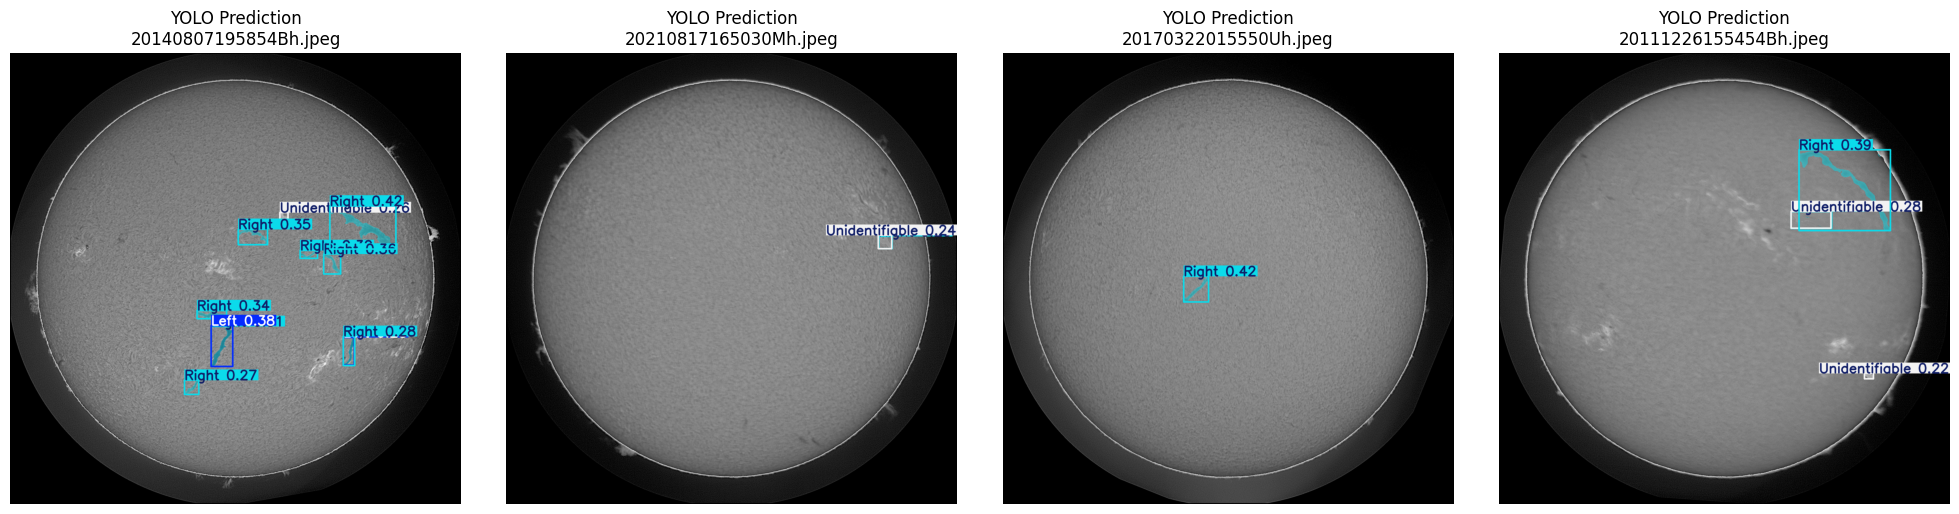

In [3]:
# ============================================================
# 18. VISUALIZATION 2
# YOLO VALIDATION PREDICTIONS
# ============================================================

print("\nGenerating validation prediction visualization...")

sample_val_files = []

for image_id in val_ids[:4]:

    filename = images_info[image_id]["file_name"]

    path = os.path.join(
        TRAIN_IMG,
        filename
    )

    sample_val_files.append(path)


val_predictions = best_model.predict(
    source=sample_val_files,
    imgsz=IMG_SIZE,
    conf=0.20,
    iou=0.5,
    device=0,
    verbose=False
)


# YOLO's built-in result plotting
fig, axes = plt.subplots(
    1,
    len(val_predictions),
    figsize=(20, 5)
)

if len(val_predictions) == 1:
    axes = [axes]

for ax, result in zip(
    axes,
    val_predictions
):

    plotted = result.plot()

    plotted = cv2.cvtColor(
        plotted,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(plotted)

    ax.set_title(
        f"YOLO Prediction\n"
        f"{Path(result.path).name}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Visualization - original image vs. predicted segmentation, side by side


Generating original vs predicted visualization...


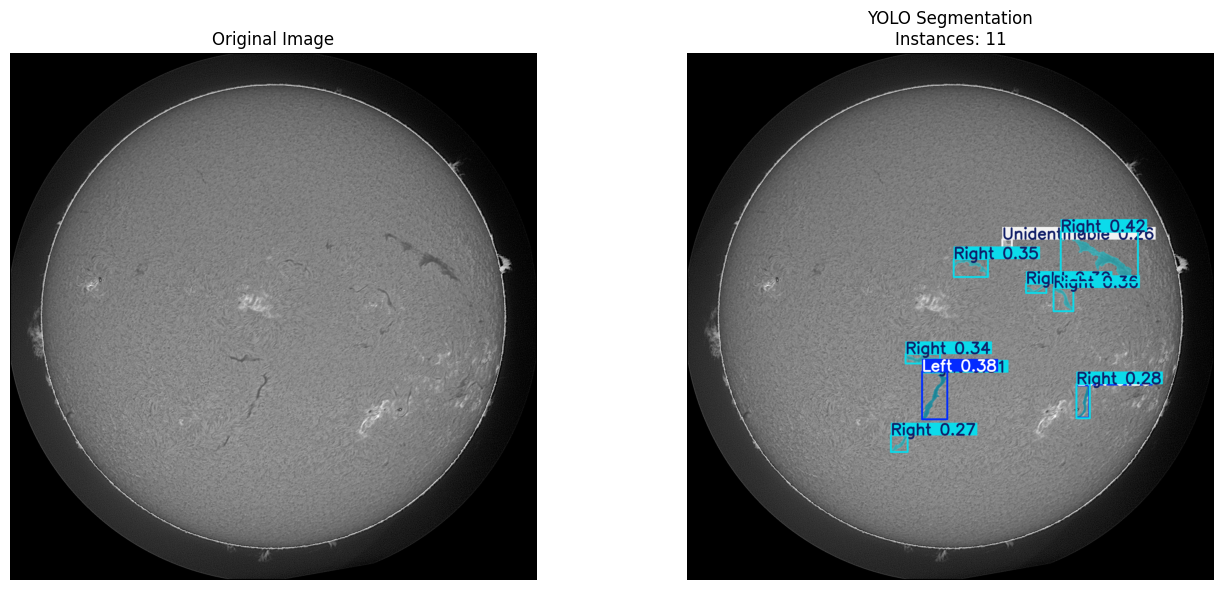

In [4]:
# ============================================================
# 19. VISUALIZATION 3
# ORIGINAL vs PREDICTED MASK
# ============================================================

print("\nGenerating original vs predicted visualization...")


def show_original_vs_prediction(
    image_path,
    model,
    conf=0.20,
    iou=0.5
):

    image = cv2.imread(image_path)

    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    results = model.predict(
        source=image_path,
        imgsz=IMG_SIZE,
        conf=conf,
        iou=iou,
        device=0,
        verbose=False
    )

    result = results[0]

    prediction = result.plot()

    prediction = cv2.cvtColor(
        prediction,
        cv2.COLOR_BGR2RGB
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 6)
    )

    axes[0].imshow(image_rgb)

    axes[0].set_title(
        "Original Image"
    )

    axes[0].axis("off")

    axes[1].imshow(prediction)

    axes[1].set_title(
        f"YOLO Segmentation\n"
        f"Instances: {len(result)}"
    )

    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


show_original_vs_prediction(
    sample_val_files[0],
    best_model
)

## 5. Final test inference -> non-overlapping submission 

- Processes **one test image at a time** (memory-safe)
- Builds masks by filling the predicted **polygon coordinates directly at full
  image resolution** (`masks.xy`) instead of resizing a low-resolution mask - sharper,
  more accurate boundaries for thin filaments
- Encodes using **proper COCO-compressed RLE** via `pycocotools` (matches what the
  grader expects - the earlier "memory-safe" attempt used a different, incompatible
  RLE text format)
- **Resolves overlapping masks live**, inside the same loop: for each image, if a
  lower-confidence detection's mask overlaps a higher-confidence one already placed,
  only the overlapping pixels are trimmed from the lower-confidence one - no genuine
  detection is deleted, so this should not reduce your score
- Self-validates the written CSV by decoding every row back and confirming zero
  overlap remains, then visualizes 5 test predictions with each instance in a
  different color so you can see the non-overlapping result directly

In [ ]:
# ============================================================
# MAGFiLO 2026 - FINAL INFERENCE + NON-OVERLAPPING SUBMISSION
# Fixes: COCO compressed RLE format, correct mask alignment,
#        gap-free filament IDs, memory-safe, self-validating,
#        AND live overlap resolution (confidence-priority) so no
#        two instances in the submission share a pixel.
# ============================================================

import os, gc, glob, subprocess, sys
from pathlib import Path

try:
    from pycocotools import mask as mask_utils
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pycocotools"])
    from pycocotools import mask as mask_utils

import cv2
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. CONFIG
# ------------------------------------------------------------
TEST_IMG_DIR = ("/kaggle/input/competitions/filament-segmentation-2026/"
                "MAGFiLO_1.0_Kaggle_2026/test/test_images")
SUBMISSION_PATH = "/kaggle/working/submission.csv"

IMG_SIZE      = 1024
CONF          = 0.20     # main confidence threshold
CONF_FALLBACK = 0.05     # used only if an image gets zero masks at CONF
IOU           = 0.50
MIN_AREA      = 5        # drop masks smaller than this many pixels

# ------------------------------------------------------------
# 2. LOCATE TRAINED MODEL (newest best.pt)
# ------------------------------------------------------------
candidates = glob.glob("/kaggle/working/runs/segment/train*/weights/best.pt")
candidates += glob.glob("/kaggle/working/**/weights/best.pt", recursive=True)
candidates = sorted(set(candidates), key=os.path.getmtime)
if not candidates:
    raise FileNotFoundError("No best.pt found under /kaggle/working. Train the model first.")

BEST_MODEL_PATH = candidates[-1]
print("Using model:", BEST_MODEL_PATH)

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = YOLO(BEST_MODEL_PATH)
device = 0 if torch.cuda.is_available() else "cpu"

# ------------------------------------------------------------
# 3. TEST IMAGES
# ------------------------------------------------------------
exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
test_files = sorted(str(p) for p in Path(TEST_IMG_DIR).glob("*") if p.suffix.lower() in exts)
print("Test images:", len(test_files))
if not test_files:
    raise RuntimeError("No test images found.")

# ------------------------------------------------------------
# 4. COCO COMPRESSED RLE ENCODER (format Kaggle expects)
# ------------------------------------------------------------
def coco_rle(binary_mask):
    rle = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    counts = rle["counts"]
    return counts.decode("utf-8") if isinstance(counts, bytes) else counts

# ------------------------------------------------------------
# 5. PREDICT ONE IMAGE -> LIST OF BINARY MASKS (original resolution)
# ------------------------------------------------------------
def predict_masks(path, h, w, conf):
    result = model.predict(source=path, imgsz=IMG_SIZE, conf=conf, iou=IOU,
                           device=device, verbose=False)[0]
    masks = []
    if result.masks is not None:
        # masks.xy = polygons already mapped back to ORIGINAL pixel coordinates
        for poly in result.masks.xy:
            if poly is None or len(poly) < 3:
                continue
            m = np.zeros((h, w), dtype=np.uint8)
            cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
            if int(m.sum()) >= MIN_AREA:
                masks.append(m)

    # ---- Resolve overlaps live, before any mask is written out ----
    # Ultralytics returns detections sorted by confidence (highest first), so
    # processing masks.xy in this order and giving each pixel to the FIRST
    # (= most confident) instance that claims it resolves overlaps without
    # deleting any genuinely unique detection - only the double-counted
    # overlapping pixels are reassigned. A mask that ends up fully covered by
    # a higher-confidence mask (zero unique pixels left) is dropped, since it
    # was a redundant duplicate detection, not a distinct filament.
    claimed = np.zeros((h, w), dtype=bool)
    non_overlapping_masks = []
    for m in masks:
        clean = (m.astype(bool)) & ~claimed
        if not clean.any():
            continue
        claimed |= clean
        non_overlapping_masks.append(clean.astype(np.uint8))
    masks = non_overlapping_masks

    del result
    return masks

# ------------------------------------------------------------
# 6. RUN INFERENCE
# ------------------------------------------------------------
rows, image_sizes, empty_images = [], {}, []

for idx, path in enumerate(test_files, 1):
    stem = Path(path).stem
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"[{idx}/{len(test_files)}] could not read {stem}")
        continue
    h, w = img.shape
    image_sizes[stem] = (h, w)

    try:
        masks = predict_masks(path, h, w, CONF)
        if not masks:                                   # retry with lower threshold
            masks = predict_masks(path, h, w, CONF_FALLBACK)
    except torch.cuda.OutOfMemoryError:
        gc.collect(); torch.cuda.empty_cache()
        print(f"[{idx}/{len(test_files)}] {stem}: CUDA OOM, skipped")
        masks = []

    for k, m in enumerate(masks, start=1):              # IDs 1..N with no gaps
        rows.append({"filament_id": f"{stem}_{k}", "segmentation_rle": coco_rle(m)})

    if not masks:
        empty_images.append(stem)
    print(f"[{idx}/{len(test_files)}] {stem}: {len(masks)} masks")

    del masks
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# 7. SAVE CSV
# ------------------------------------------------------------
submission = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
submission.to_csv(SUBMISSION_PATH, index=False)


Using model: /kaggle/working/runs/segment/train/weights/best.pt
Test images: 180
[1/180] 20110120105534Ch: 3 masks
[2/180] 20110130110334Ch: 2 masks
[3/180] 20110214175414Mh: 3 masks
[4/180] 20110329082654Uh: 7 masks
[5/180] 20110408083214Th: 7 masks
[6/180] 20110424064534Lh: 8 masks
[7/180] 20110429120534Ch: 10 masks
[8/180] 20110529063154Uh: 4 masks
[9/180] 20110531070514Th: 10 masks
[10/180] 20110603123034Ch: 11 masks
[11/180] 20110706164014Mh: 4 masks
[50/180] 20130206063154Uh: 7 masks
[100/180] 20150623152934Ch: 6 masks
[150/180] 20171122022450Uh: 3 masks
[180/180] 20220728185352Th: 3 masks

SUBMISSION READY
Rows                  : 1125
Images with masks     : 180 / 180
Undecodable RLE rows  : 0
Images with 0 masks   : 0 []
File                  : /kaggle/working/submission.csv (0.34 MB)
